**NAME:** YASH GALANDE  
**PRN:** 202401040179  
**ROLL NO:** 41  
**BATCH:** A2  
**GITHUB LINK:** *(add your repository link here)*

# LAB Assignment 4: Regression Models for a Real-World Application and Gradient Descent Analysis

## Aim
1. Develop regression models for a real-world application (**house price prediction**) and evaluate their performance using appropriate metrics.
2. Implement and analyze the performance of Gradient Descent optimization for Linear Regression.

## Problem Statement
A real-estate company wants to estimate the selling price of a house from its characteristics: built-up area, number of bedrooms, age of the house and distance from the city centre. Price is a continuous value, so this is a regression problem. Several regression models are built and compared. Gradient Descent is then implemented from scratch and its behaviour is studied for different learning rates and numbers of iterations.

## Objectives
1. Build Simple, Multiple and Polynomial Regression models for house price prediction.
2. Evaluate the models using MAE, MSE, RMSE and R².
3. Implement Batch Gradient Descent for Linear Regression from scratch.
4. Study the effect of learning rate and iterations on convergence.
5. Compare Gradient Descent with the closed-form (library) solution.

## Dataset Description
A house-price dataset of **500 houses** is generated in the notebook with a fixed random seed (`seed = 7`), so results are reproducible. The values follow realistic relationships: price rises with area and bedrooms and falls with age and distance from the city. A small non-linear term in area and random noise are included, as in real data.

| Feature | Meaning | Unit |
|---|---|---|
| `Area` | Built-up area | sq. ft |
| `Bedrooms` | Number of bedrooms | count |
| `Age` | Age of the house | years |
| `Distance` | Distance from city centre | km |
| `Price` (target) | Selling price | ₹ lakhs |

*To use a real dataset (e.g. a Kaggle housing CSV), replace the data-generation cell with `pd.read_csv(...)` and keep the same column names. The rest of the notebook works unchanged.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.set_printoptions(suppress=True)
print("Libraries imported successfully")

Libraries imported successfully


## 1. Dataset Creation and Exploration

In [2]:
rng = np.random.default_rng(7)
n = 500

area      = rng.uniform(500, 3500, n)
bedrooms  = np.clip(np.round(area / 900 + rng.normal(0, 0.7, n)), 1, 5)
age       = rng.uniform(0, 40, n)
distance  = rng.uniform(1, 30, n)

price = (35 + 0.020 * area + 0.000012 * area ** 2 + 3.0 * bedrooms
         - 0.5 * age - 1.0 * distance + rng.normal(0, 8, n))
price = np.clip(price, 8, None)   # prices (in lakhs) cannot be negative

house_df = pd.DataFrame({"Area": area.round(0), "Bedrooms": bedrooms,
                         "Age": age.round(1), "Distance": distance.round(1),
                         "Price": price.round(2)})

display(house_df.head())
print("Shape:", house_df.shape)
print("Missing values:", int(house_df.isna().sum().sum()))
display(house_df.describe().round(2))

,Area,Bedrooms,Age,Distance,Price
0,2375.0,3.0,32.0,2.0,131.54
1,3192.0,4.0,36.9,9.6,212.32
2,2827.0,2.0,5.7,24.3,160.86
3,1176.0,1.0,0.5,27.8,49.45
4,1400.0,1.0,10.5,18.3,71.05


Shape: (500, 5)
Missing values: 0


,Area,Bedrooms,Age,Distance,Price
count,500.00,500.00,500.00,500.00,500.00
mean,2031.09,2.32,20.37,15.59,115.04
std,855.85,1.09,11.46,8.25,62.50
min,511.00,1.00,0.00,1.10,8.00
25%,1263.25,1.00,11.30,8.80,61.94
50%,2061.00,2.00,20.10,15.20,106.26
75%,2774.25,3.00,29.80,23.20,165.17
max,3497.00,5.00,40.00,29.80,265.64


,Area,Bedrooms,Age,Distance,Price
Area,1.000,0.800,0.039,0.043,0.967
Bedrooms,0.800,1.000,0.073,0.049,0.790
Age,0.039,0.073,1.000,0.048,-0.071
Distance,0.043,0.049,0.048,1.000,-0.102
Price,0.967,0.790,-0.071,-0.102,1.000


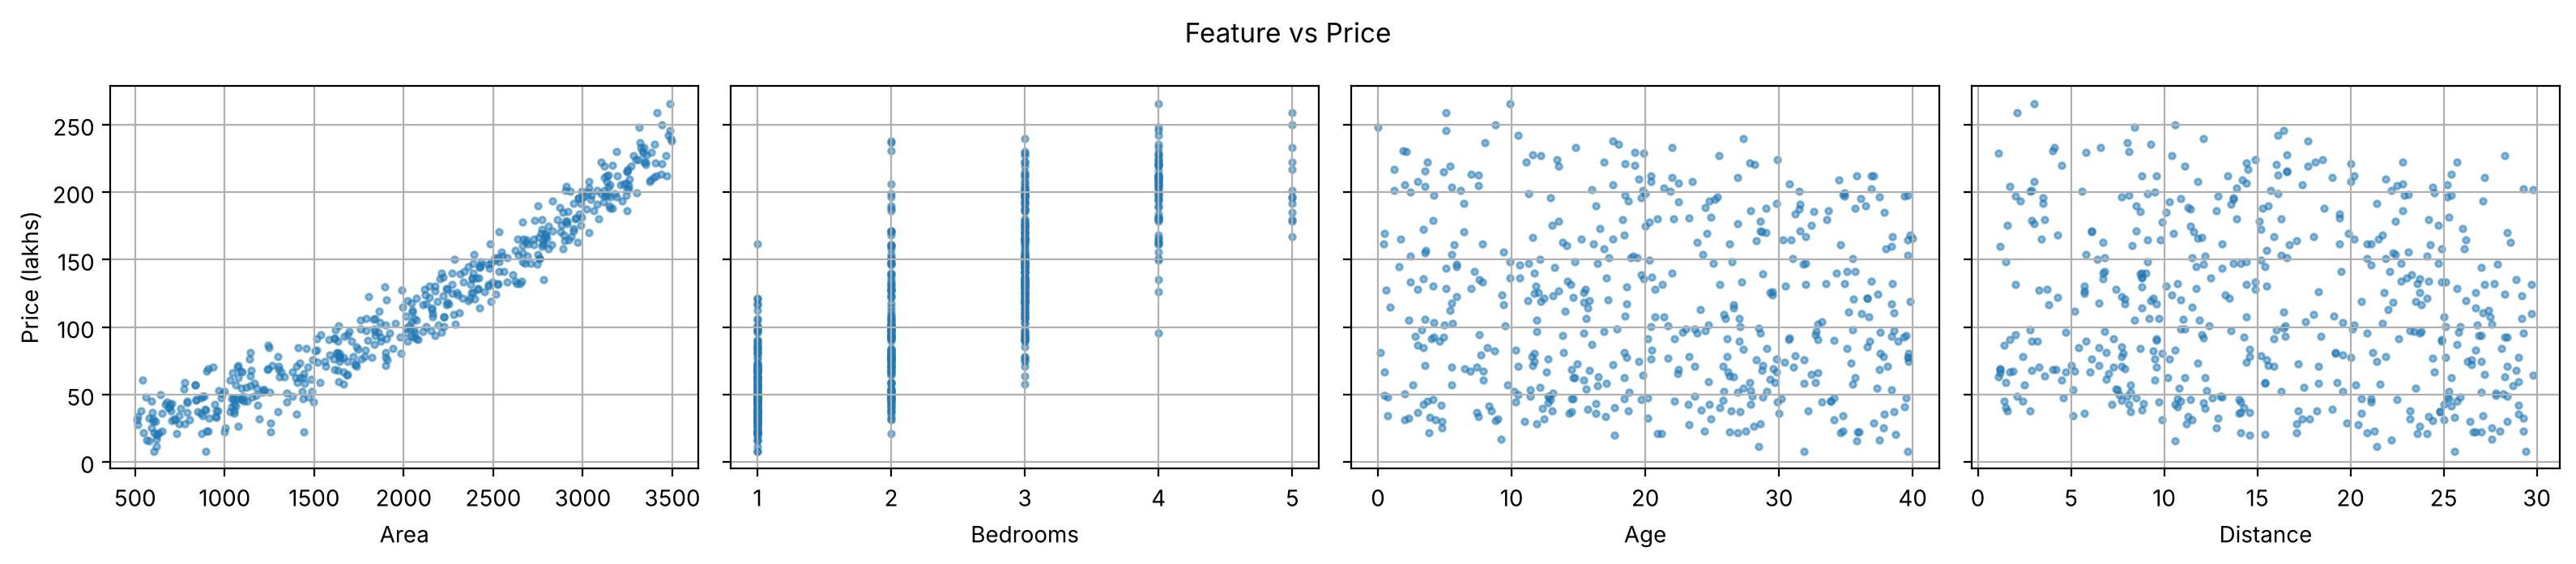

In [3]:
# Correlation of each feature with the target
corr = house_df.corr().round(3)
display(corr)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for a, col in zip(ax, ["Area", "Bedrooms", "Age", "Distance"]):
    a.scatter(house_df[col], house_df["Price"], s=8, alpha=0.5)
    a.set_xlabel(col); a.grid(True)
ax[0].set_ylabel("Price (lakhs)")
plt.suptitle("Feature vs Price"); plt.tight_layout(); plt.show()

**Observation:** Area and Bedrooms are positively correlated with Price. Age and Distance are negatively correlated. Area and Bedrooms are also correlated with each other, which is expected.

## 2. Train/Test Split and Evaluation Function

In [4]:
features = ["Area", "Bedrooms", "Age", "Distance"]
X = house_df[features]
y = house_df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("Training samples:", len(X_train), "| Testing samples:", len(X_test))

def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

results = {}   # stores the metrics of every model

Training samples: 400 | Testing samples: 100


## 3. Simple Linear Regression (Area → Price)
Model: **y = m·x + c**. Only `Area` is used as the input, to see how much of the price one feature explains.

Equation: Price = 0.0702 x Area + -27.13


,MAE,MSE,RMSE,R2
Simple Linear (Area),13.9553,281.6514,16.7825,0.9273


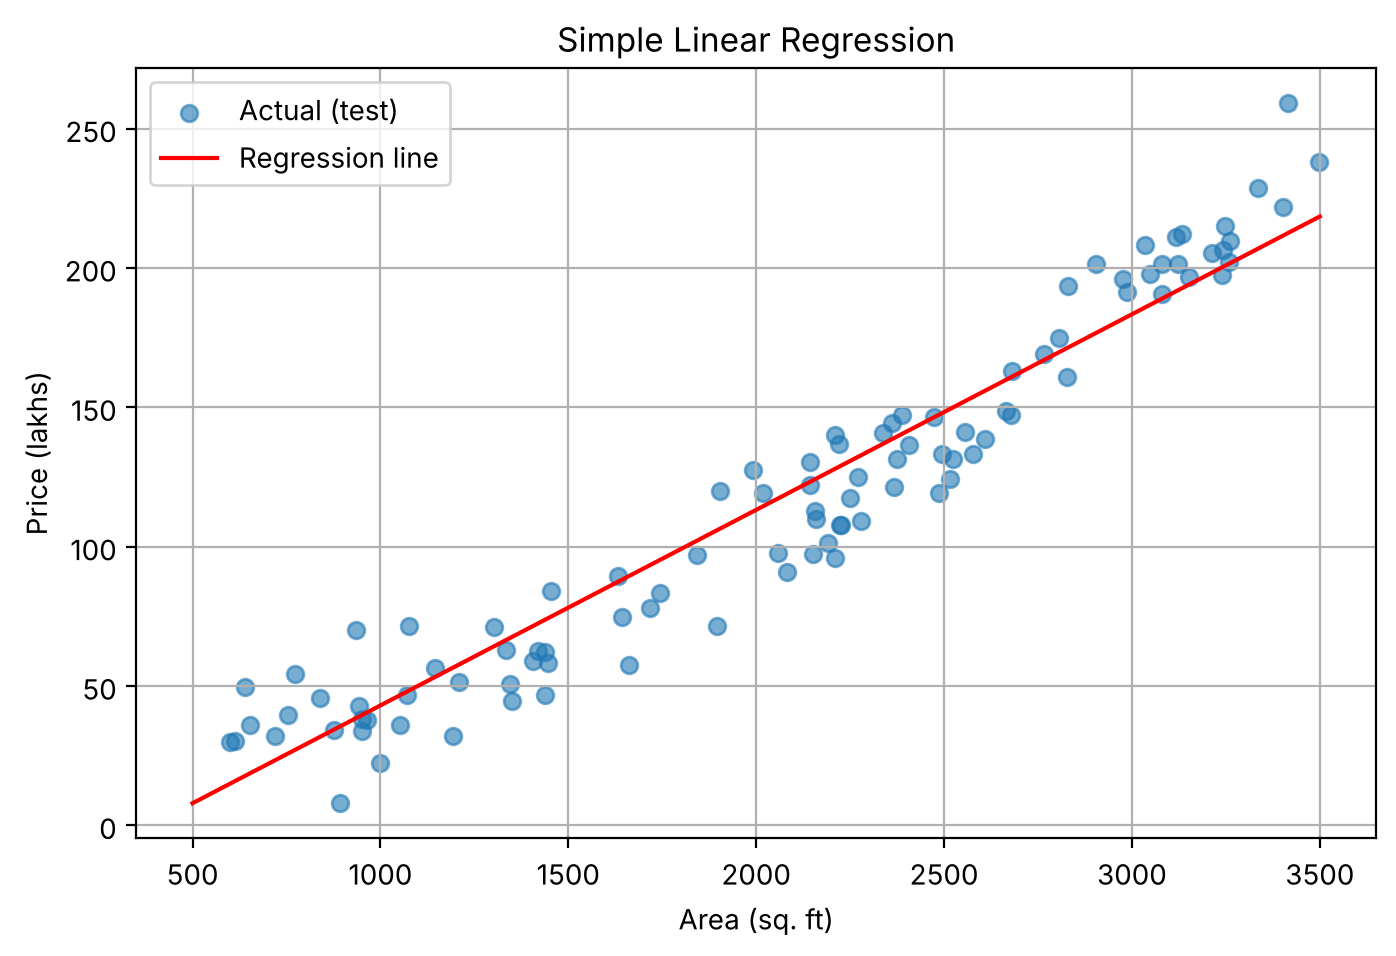

In [5]:
slr = LinearRegression().fit(X_train[["Area"]], y_train)
pred_slr = slr.predict(X_test[["Area"]])

print(f"Equation: Price = {slr.coef_[0]:.4f} x Area + {slr.intercept_:.2f}")
results["Simple Linear (Area)"] = evaluate(y_test, pred_slr)
display(pd.DataFrame(results).T.round(4))

xs = np.linspace(500, 3500, 100).reshape(-1, 1)
plt.figure(figsize=(8, 5))
plt.scatter(X_test["Area"], y_test, alpha=0.6, label="Actual (test)")
plt.plot(xs, slr.predict(pd.DataFrame(xs, columns=["Area"])), "r", label="Regression line")
plt.xlabel("Area (sq. ft)"); plt.ylabel("Price (lakhs)")
plt.title("Simple Linear Regression"); plt.legend(); plt.grid(True); plt.show()

## 4. Multiple Linear Regression (all 4 features)
Model: **y = b₀ + b₁x₁ + b₂x₂ + … + bₙxₙ**

Intercept: -2.5848


,Feature,Coefficient
0,Area,0.0676
1,Bedrooms,3.5050
2,Age,-0.5369
3,Distance,-1.0768


,MAE,MSE,RMSE,R2
Simple Linear (Area),13.9553,281.6514,16.7825,0.9273
Multiple Linear,9.4406,125.8519,11.2184,0.9675


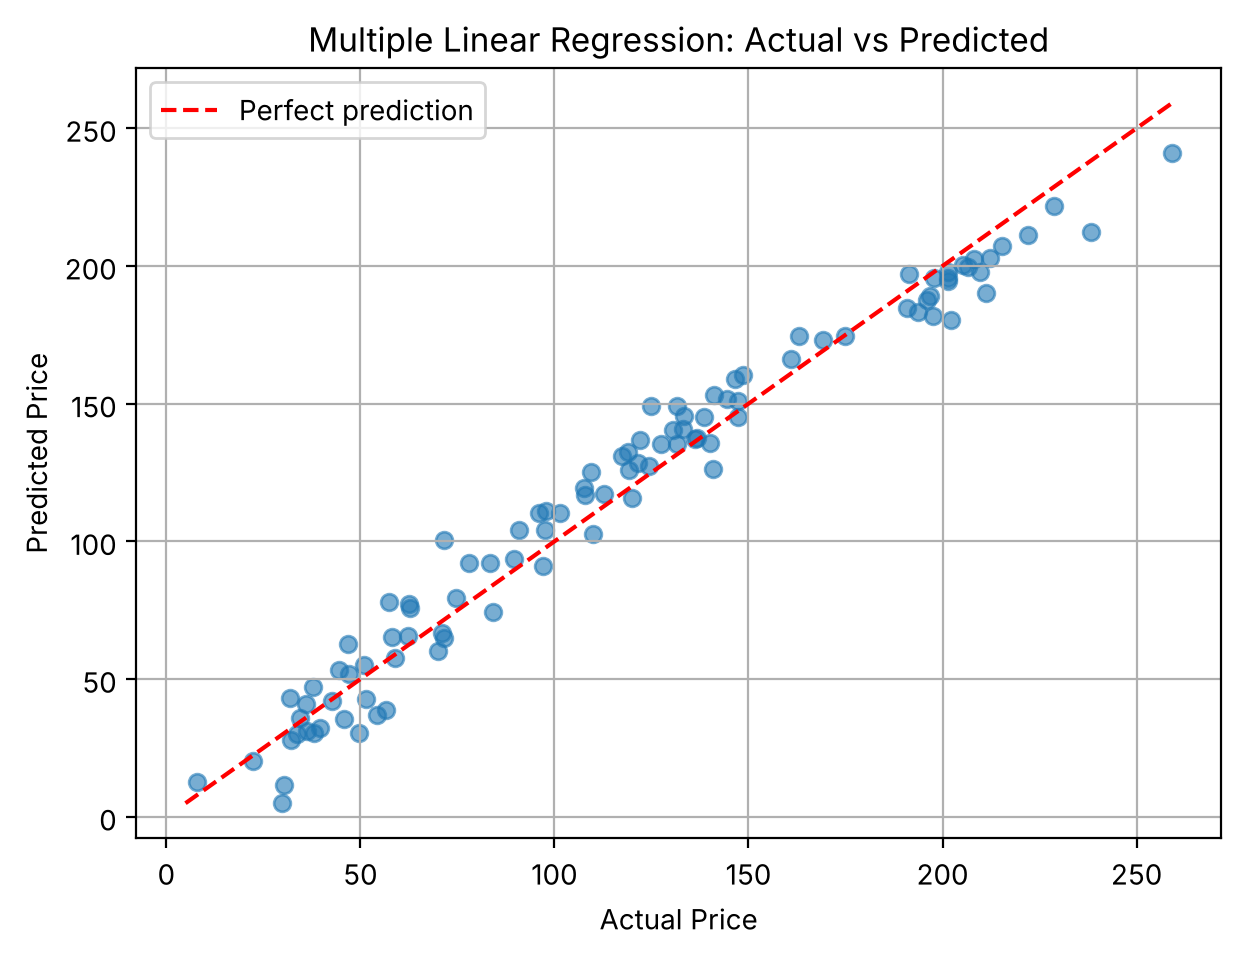

In [6]:
mlr = LinearRegression().fit(X_train, y_train)
pred_mlr = mlr.predict(X_test)

print("Intercept:", round(mlr.intercept_, 4))
display(pd.DataFrame({"Feature": features, "Coefficient": mlr.coef_}).round(4))

results["Multiple Linear"] = evaluate(y_test, pred_mlr)
display(pd.DataFrame(results).T.round(4))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, pred_mlr, alpha=0.6)
lo, hi = min(y_test.min(), pred_mlr.min()), max(y_test.max(), pred_mlr.max())
plt.plot([lo, hi], [lo, hi], "r--", label="Perfect prediction")
plt.xlabel("Actual Price"); plt.ylabel("Predicted Price")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.legend(); plt.grid(True); plt.show()

## 5. Polynomial Regression (Area, degrees 1 to 4)
Polynomial Regression adds powers of the feature (**y = b₀ + b₁x + b₂x² + …**) to capture curved relationships. Several degrees are compared on the **test set** to detect under-fitting and over-fitting.

In [7]:
rows = []
for d in [1, 2, 3, 4]:
    pm = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression())
    pm.fit(X_train[["Area"]], y_train)
    tr = r2_score(y_train, pm.predict(X_train[["Area"]]))
    te = evaluate(y_test, pm.predict(X_test[["Area"]]))
    rows.append({"Degree": d, "Train R2": tr, **{k: v for k, v in te.items()}})
poly_table = pd.DataFrame(rows).set_index("Degree")
display(poly_table.round(4))

,Train R2,MAE,MSE,RMSE,R2
Degree,,,,,
1,0.9365,13.9553,281.6514,16.7825,0.9273
2,0.9572,10.9153,177.0521,13.3061,0.9543
3,0.9572,10.9263,177.2120,13.3121,0.9543
4,0.9572,10.9161,177.4478,13.3210,0.9542


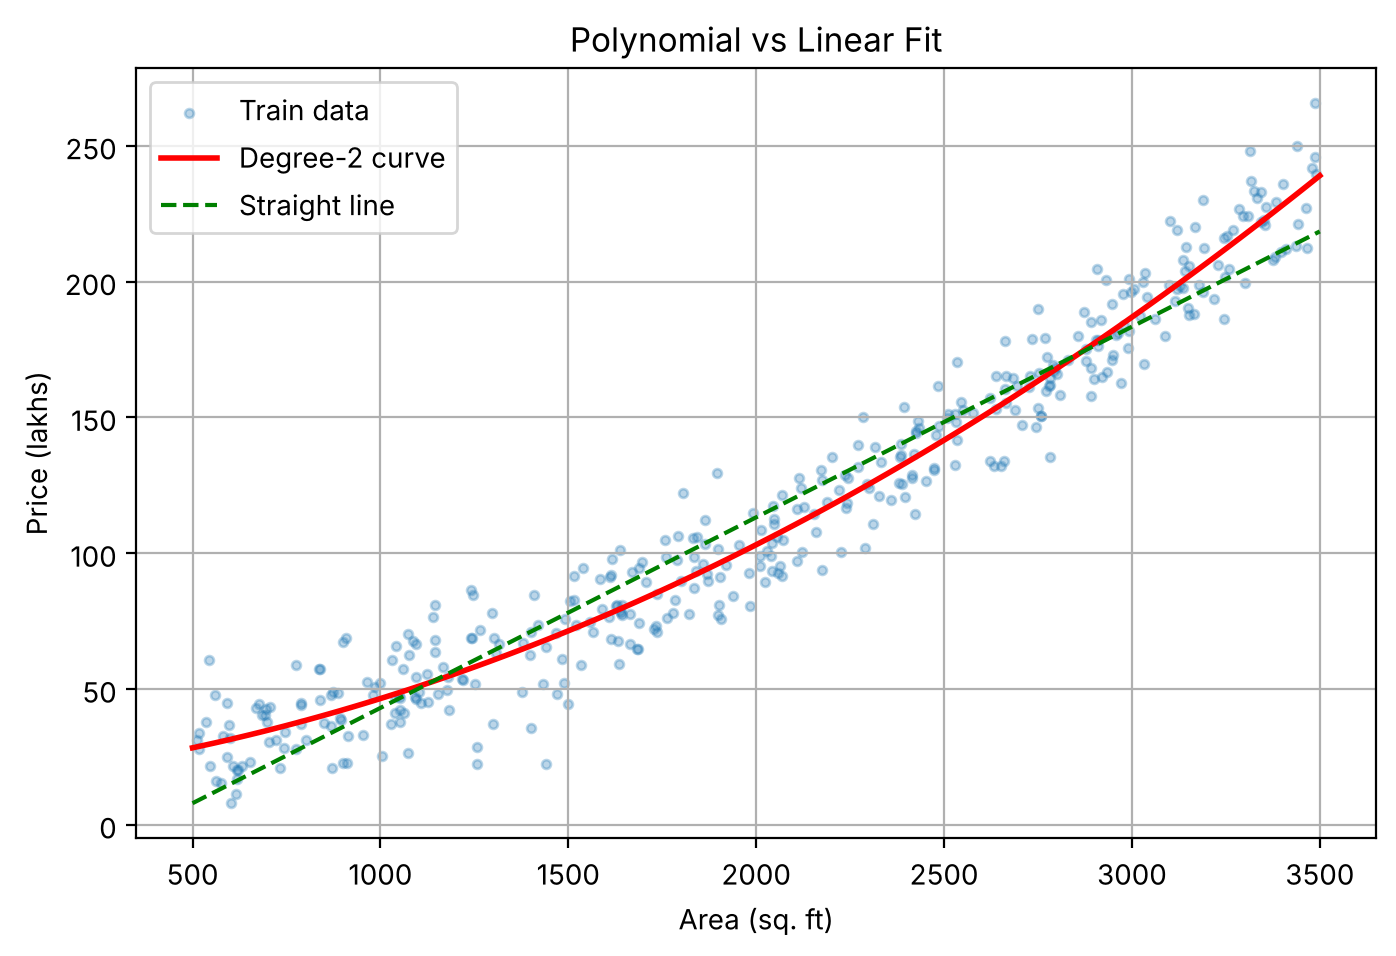

In [8]:
# Use degree 2 on Area for the final polynomial model
poly = make_pipeline(PolynomialFeatures(2), StandardScaler(), LinearRegression())
poly.fit(X_train[["Area"]], y_train)
results["Polynomial (deg 2, Area)"] = evaluate(y_test, poly.predict(X_test[["Area"]]))

plt.figure(figsize=(8, 5))
plt.scatter(X_train["Area"], y_train, s=10, alpha=0.3, label="Train data")
plt.plot(xs, poly.predict(pd.DataFrame(xs, columns=["Area"])), "r", lw=2, label="Degree-2 curve")
plt.plot(xs, slr.predict(pd.DataFrame(xs, columns=["Area"])), "g--", label="Straight line")
plt.xlabel("Area (sq. ft)"); plt.ylabel("Price (lakhs)")
plt.title("Polynomial vs Linear Fit"); plt.legend(); plt.grid(True); plt.show()

## 6. Gradient Descent for Linear Regression (from scratch)

Gradient Descent finds the parameters θ that minimize the cost function

**J(θ) = (1/2m) Σ (Xθ − y)²**

by repeatedly stepping in the direction opposite to the gradient:

**θ := θ − α · (1/m) · Xᵀ(Xθ − y)**

where α is the learning rate and m is the number of training samples. Features are **standardized** (mean 0, std 1) using training statistics only, so that all parameters converge at a similar rate. The target is left in its original units (lakhs), so the learned parameters are directly comparable with the closed-form solution.

In [9]:
# Standardize features (training statistics only, no leakage)
scaler = StandardScaler()
Xtr_s = scaler.fit_transform(X_train)
Xte_s = scaler.transform(X_test)

# Add a column of ones for the intercept
Xtr_b = np.c_[np.ones(len(Xtr_s)), Xtr_s]
Xte_b = np.c_[np.ones(len(Xte_s)), Xte_s]
ytr = y_train.to_numpy(dtype=float)

def gradient_descent(X, y, alpha=0.1, iters=1000):
    m = len(y)
    theta = np.zeros(X.shape[1])
    history = []
    for _ in range(iters):
        err = X @ theta - y
        history.append(np.sum(err ** 2) / (2 * m))      # cost J(theta)
        theta = theta - alpha * (X.T @ err) / m          # update rule
    history.append(np.sum((X @ theta - y) ** 2) / (2 * m))
    return theta, np.array(history)

theta_gd, cost_hist = gradient_descent(Xtr_b, ytr, alpha=0.1, iters=1000)
pred_gd = Xte_b @ theta_gd

print("Initial cost:", round(cost_hist[0], 4))
print("Final cost  :", round(cost_hist[-1], 4))
results["Gradient Descent"] = evaluate(y_test, pred_gd)
display(pd.DataFrame(results).T.round(4))

Initial cost: 8523.561
Final cost  : 63.9348


,MAE,MSE,RMSE,R2
Simple Linear (Area),13.9553,281.6514,16.7825,0.9273
Multiple Linear,9.4406,125.8519,11.2184,0.9675
"Polynomial (deg 2, Area)",10.9153,177.0521,13.3061,0.9543
Gradient Descent,9.4406,125.8519,11.2184,0.9675


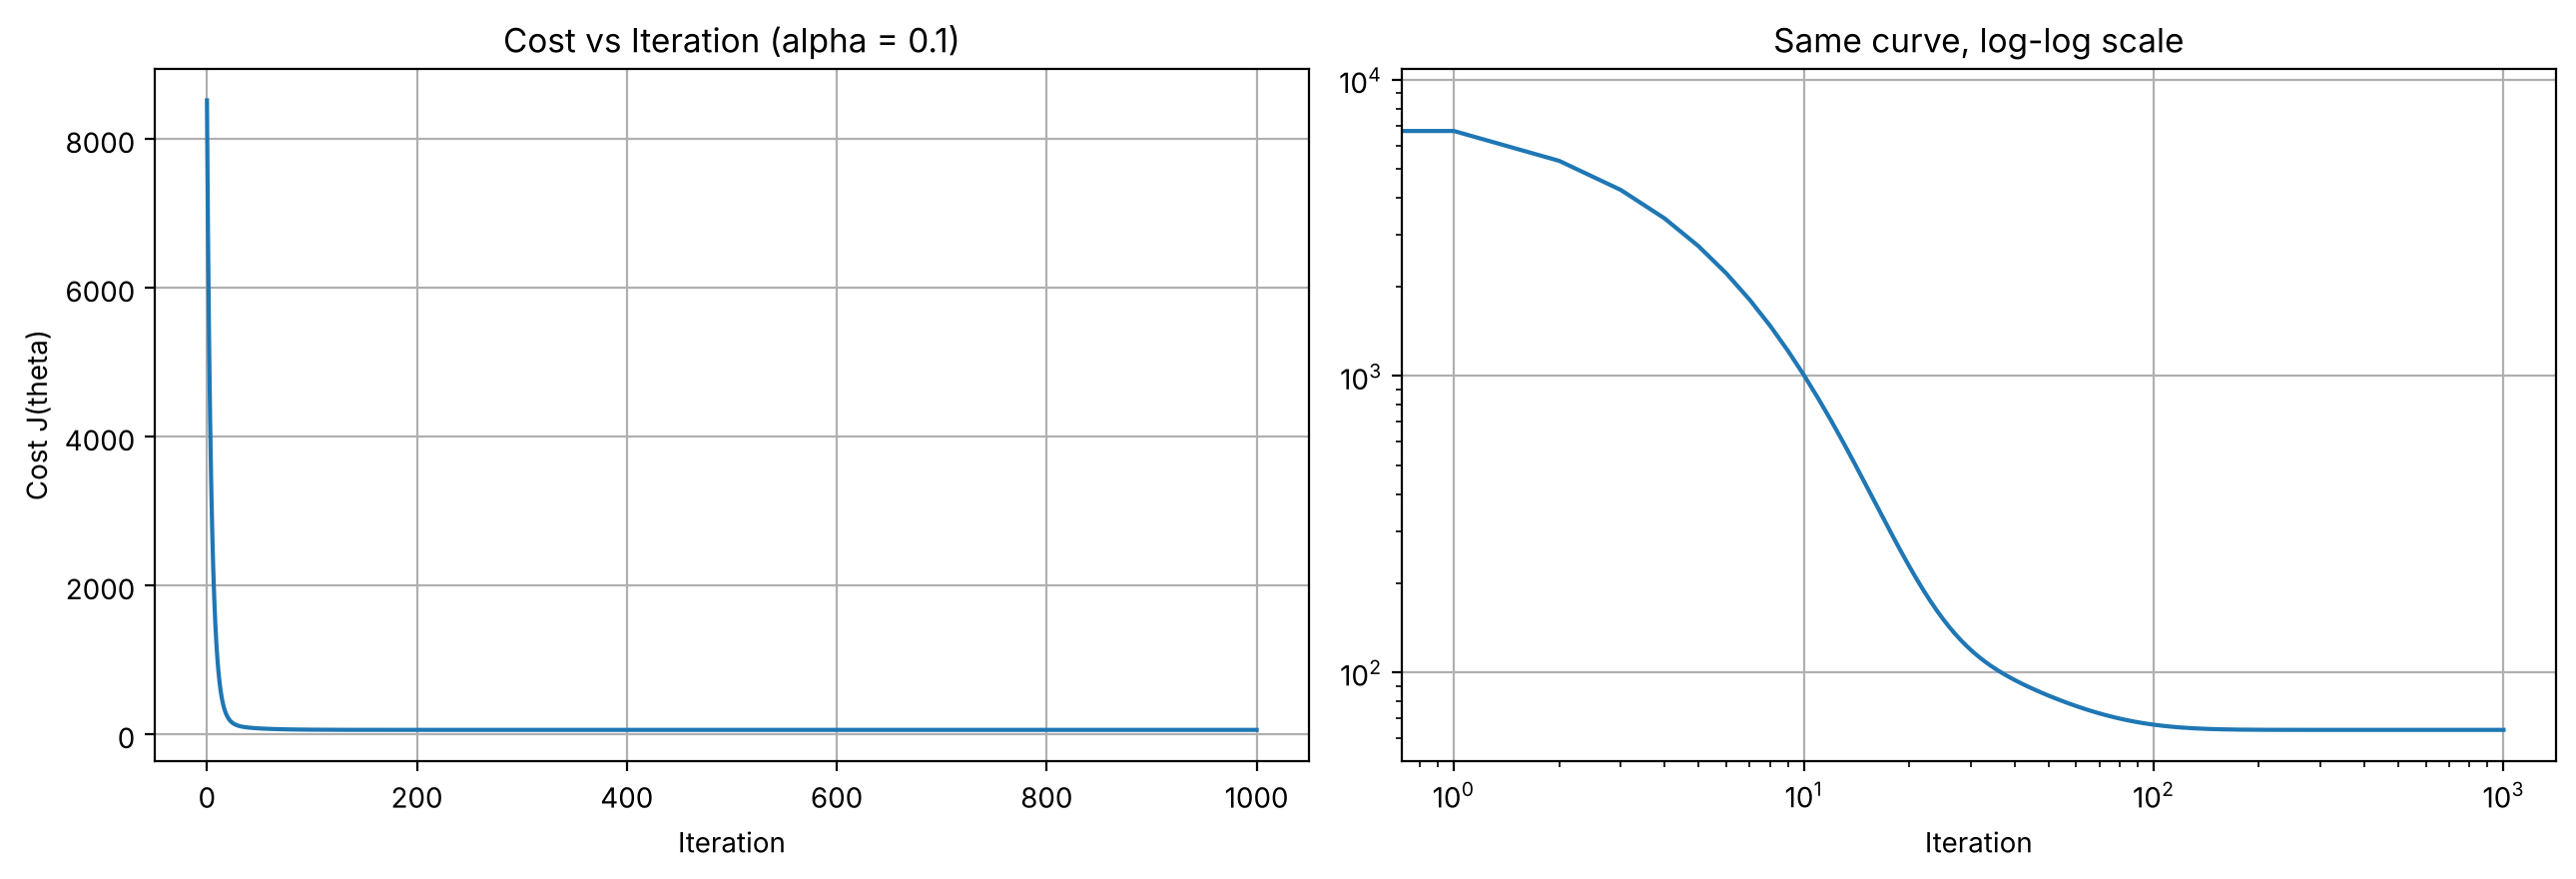

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(cost_hist); ax[0].set_title("Cost vs Iteration (alpha = 0.1)")
ax[0].set_xlabel("Iteration"); ax[0].set_ylabel("Cost J(theta)"); ax[0].grid(True)
ax[1].plot(cost_hist); ax[1].set_yscale("log"); ax[1].set_xscale("log")
ax[1].set_title("Same curve, log-log scale"); ax[1].set_xlabel("Iteration"); ax[1].grid(True)
plt.tight_layout(); plt.show()

### 6.1 Verification: Gradient Descent vs Closed-Form (Library) Solution

In [11]:
# Library solution on the same standardized features
lib = LinearRegression().fit(Xtr_s, ytr)
theta_lib = np.r_[lib.intercept_, lib.coef_]

cmp = pd.DataFrame({"Parameter": ["Intercept"] + features,
                    "Gradient Descent": theta_gd,
                    "LinearRegression": theta_lib})
cmp["Difference"] = (cmp["Gradient Descent"] - cmp["LinearRegression"]).abs()
display(cmp.round(6))

print("Max parameter difference:", f"{cmp['Difference'].max():.2e}")
print("Max prediction difference on test set:",
      f"{np.max(np.abs(pred_gd - lib.predict(Xte_s))):.2e}")

,Parameter,Gradient Descent,LinearRegression,Difference
0,Intercept,114.647225,114.647225,0.0
1,Area,58.269947,58.269947,0.0
2,Bedrooms,3.810541,3.810541,0.0
3,Age,-6.215140,-6.215140,0.0
4,Distance,-8.800772,-8.800772,0.0


Max parameter difference: 5.90e-08
Max prediction difference on test set: 1.18e-07


## 7. Analysis of Gradient Descent

### 7.1 Effect of Learning Rate (α)
The same model is trained with different learning rates for 200 iterations.

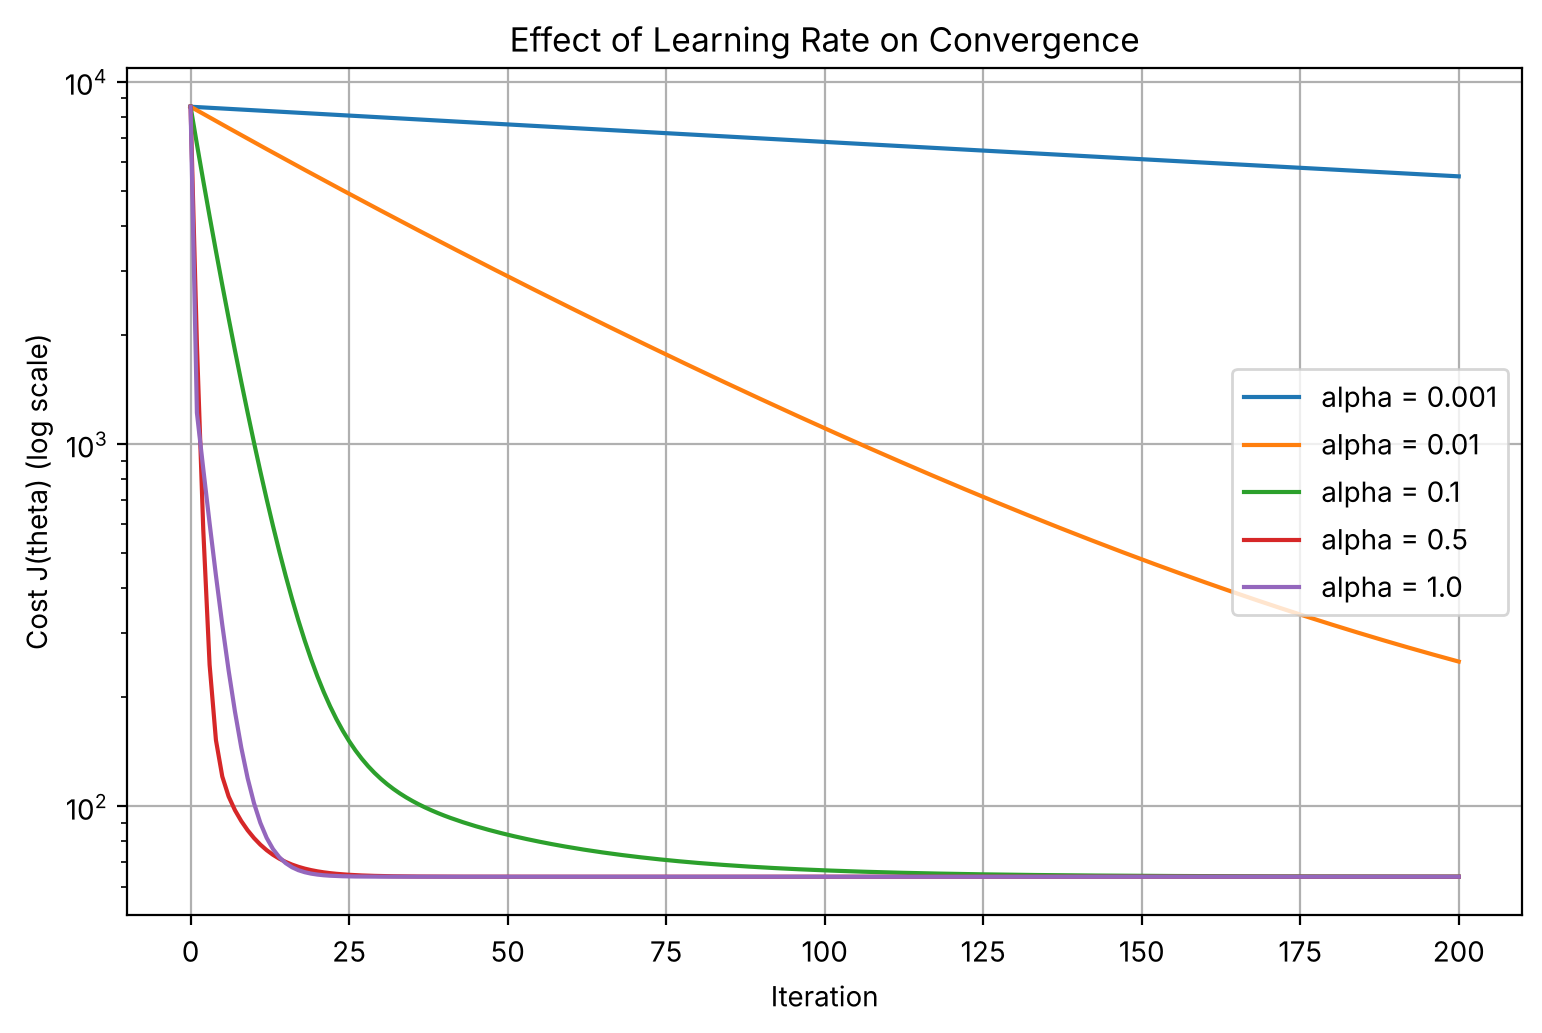

,Cost @ iter 10,Cost @ iter 100,Final cost (200),Test R2
alpha,,,,
0.001,8333.2138,6815.5992,5476.0563,-1.9096
0.010,6807.3001,1104.8555,250.8436,0.8660
0.100,1009.2108,66.5745,63.9837,0.9676
0.500,81.7529,63.9348,63.9348,0.9675
1.000,102.0499,63.9348,63.9348,0.9675


In [12]:
alphas = [0.001, 0.01, 0.1, 0.5, 1.0]
plt.figure(figsize=(9, 5.5))
rows = []
for a in alphas:
    th, h = gradient_descent(Xtr_b, ytr, alpha=a, iters=200)
    plt.plot(h, label=f"alpha = {a}")
    rows.append({"alpha": a, "Cost @ iter 10": h[10], "Cost @ iter 100": h[100],
                 "Final cost (200)": h[-1],
                 "Test R2": r2_score(y_test, Xte_b @ th)})
plt.yscale("log"); plt.xlabel("Iteration"); plt.ylabel("Cost J(theta) (log scale)")
plt.title("Effect of Learning Rate on Convergence"); plt.legend(); plt.grid(True); plt.show()
lr_table = pd.DataFrame(rows).set_index("alpha")
display(lr_table.round(4))

### 7.2 Effect of Number of Iterations
With α = 0.1, test performance is recorded after a different number of iterations. The minimum possible cost (closed-form solution) is shown for reference.

In [13]:
best_cost = np.sum((Xtr_b @ theta_lib - ytr) ** 2) / (2 * len(ytr))
rows = []
for it in [1, 5, 10, 25, 50, 100, 500, 1000]:
    th, h = gradient_descent(Xtr_b, ytr, alpha=0.1, iters=it)
    e = evaluate(y_test, Xte_b @ th)
    rows.append({"Iterations": it, "Train cost": h[-1],
                 "Gap to optimum": h[-1] - best_cost,
                 "Test RMSE": e["RMSE"], "Test R2": e["R2"]})
display(pd.DataFrame(rows).set_index("Iterations").round(4))
print("Minimum (closed-form) training cost:", round(best_cost, 4))

,Train cost,Gap to optimum,Test RMSE,Test R2
Iterations,,,,
1,6717.1102,6653.1754,117.5014,-2.5621
5,2745.5828,2681.6480,75.4401,-0.4683
10,1009.2108,945.2760,45.9254,0.4558
25,151.3567,87.4219,17.4581,0.9214
50,83.4982,19.5634,12.5951,0.9591
100,66.5745,2.6397,11.3371,0.9668
500,63.9348,0.0000,11.2183,0.9675
1000,63.9348,-0.0000,11.2184,0.9675


Minimum (closed-form) training cost: 63.9348


### 7.3 Importance of Feature Scaling
Gradient Descent is run on the **raw (unscaled)** features with a small learning rate and compared with the scaled version for the same number of iterations.

Cost after 1000 iterations -> scaled   : 63.9348
Cost after 1000 iterations -> unscaled : 176.7933
Test R2 -> unscaled GD: 0.8908


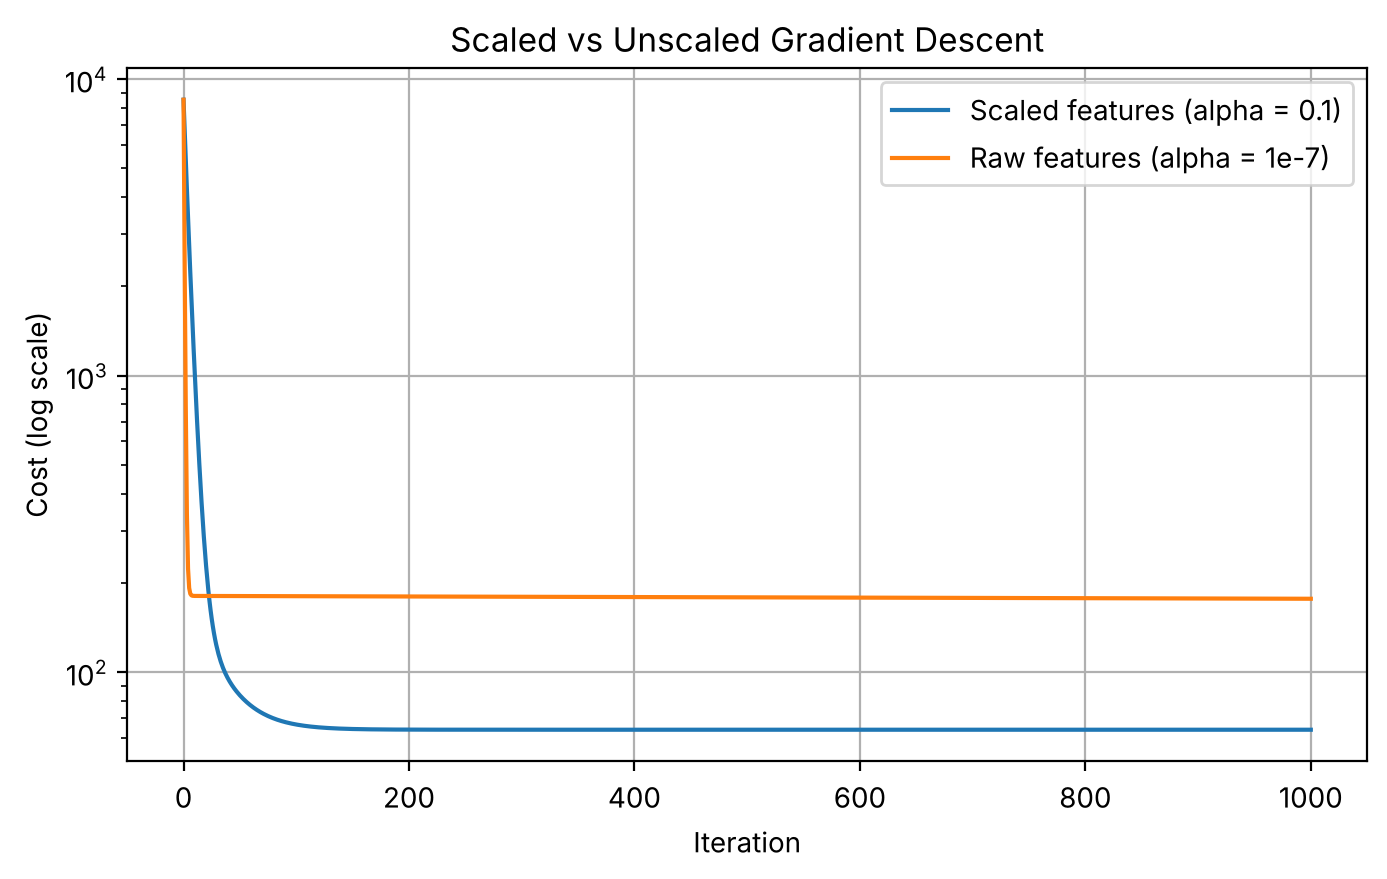

In [14]:
Xtr_raw = np.c_[np.ones(len(X_train)), X_train.to_numpy(dtype=float)]
Xte_raw = np.c_[np.ones(len(X_test)), X_test.to_numpy(dtype=float)]

# alpha must be tiny, otherwise the unscaled problem diverges
th_raw, h_raw = gradient_descent(Xtr_raw, ytr, alpha=1e-7, iters=1000)
_, h_scaled = gradient_descent(Xtr_b, ytr, alpha=0.1, iters=1000)

print("Cost after 1000 iterations -> scaled   :", round(h_scaled[-1], 4))
print("Cost after 1000 iterations -> unscaled :", round(h_raw[-1], 4))
print("Test R2 -> unscaled GD:", round(r2_score(y_test, Xte_raw @ th_raw), 4))

plt.figure(figsize=(8, 4.5))
plt.plot(h_scaled, label="Scaled features (alpha = 0.1)")
plt.plot(h_raw, label="Raw features (alpha = 1e-7)")
plt.yscale("log"); plt.xlabel("Iteration"); plt.ylabel("Cost (log scale)")
plt.title("Scaled vs Unscaled Gradient Descent"); plt.legend(); plt.grid(True); plt.show()

## 8. Performance Comparison of All Models

,MAE,MSE,RMSE,R2
Simple Linear (Area),13.9553,281.6514,16.7825,0.9273
Multiple Linear,9.4406,125.8519,11.2184,0.9675
"Polynomial (deg 2, Area)",10.9153,177.0521,13.3061,0.9543
Gradient Descent,9.4406,125.8519,11.2184,0.9675


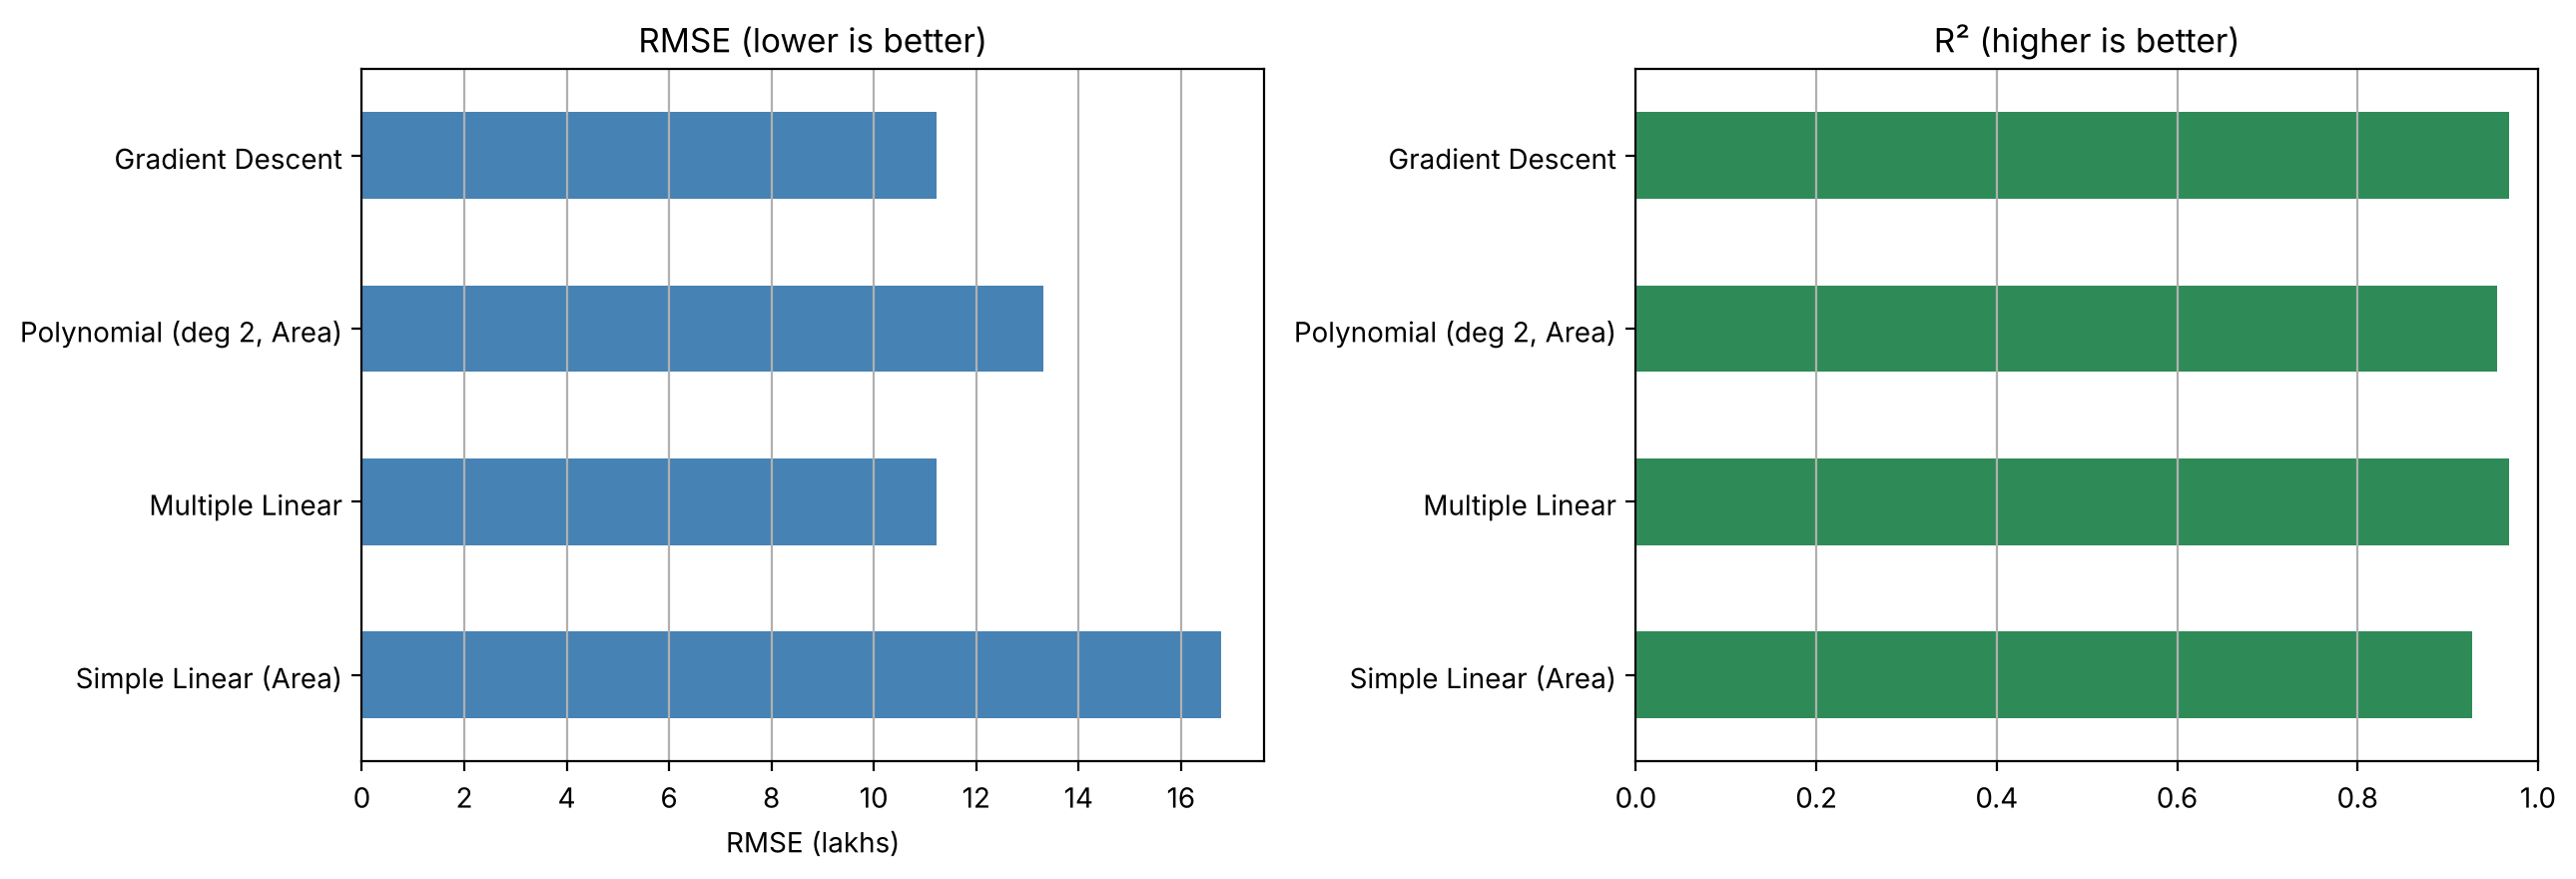

In [15]:
comparison = pd.DataFrame(results).T
display(comparison.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
comparison["RMSE"].plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].set_title("RMSE (lower is better)"); ax[0].set_xlabel("RMSE (lakhs)")
comparison["R2"].plot(kind="barh", ax=ax[1], color="seagreen")
ax[1].set_title("R² (higher is better)"); ax[1].set_xlim(0, 1)
for a in ax: a.grid(True, axis="x")
plt.tight_layout(); plt.show()

## Theory: Evaluation Metrics

- **MAE** – average absolute difference between actual and predicted values (here in ₹ lakhs); easy to interpret.
- **MSE** – average of squared errors; penalizes large errors more.
- **RMSE** – square root of MSE; in the same units as the target.
- **R²** – fraction of the variation in the target explained by the model (1 = perfect, 0 = same as predicting the mean, negative = worse than the mean).

No single metric should be used alone. MAE and RMSE show the size of the typical error and R² shows how well the model explains the data. All models here are evaluated on the same unseen test set, so the comparison is fair.

## Results and Observations

**Part 1 – Regression models for house price prediction (test set)**

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Simple Linear (Area) | 13.96 | 16.78 | 0.9273 |
| Polynomial, degree 2 (Area) | 10.92 | 13.31 | 0.9543 |
| Multiple Linear (4 features) | 9.44 | 11.22 | 0.9675 |
| Gradient Descent (4 features) | 9.44 | 11.22 | 0.9675 |

- Area alone explains about 93% of the variation in price. Adding Bedrooms, Age and Distance (Multiple Linear Regression) raises R² to 0.9675 and cuts RMSE from 16.78 to 11.22 lakhs.
- A degree-2 polynomial on Area improves on the straight line (R² 0.9273 to 0.9543) because price grows slightly faster than linearly with area. Degrees 3 and 4 give no further gain, so degree 2 is enough and higher degrees only add complexity.
- Multiple Linear Regression is the best model for this application. It uses the most information and has the lowest errors.

**Part 2 – Gradient Descent analysis**

- **Correctness:** With α = 0.1 and 1000 iterations, Gradient Descent matches the closed-form `LinearRegression` solution. Parameters differ by less than 1e-7, and the test metrics are identical to Multiple Linear Regression.
- **Learning rate:** α = 0.001 is too small. After 200 iterations the cost is still far from the minimum (test R² is negative). α = 0.01 is slow. α = 0.1 to 0.5 converge quickly and smoothly. α = 1.0 overshoots at first and then settles. Larger values may diverge, so the learning rate must be chosen with care.
- **Iterations:** The cost drops sharply in the first 50 iterations (test R² 0.9591 at 50 iterations). It is essentially at the minimum by about 100 to 500 iterations, and further iterations give no benefit.
- **Feature scaling:** On raw features Gradient Descent needs a tiny learning rate (1e-7) to stay stable and is still far from the optimum after 1000 iterations (cost 176.8 versus 63.9, test R² 0.8908 versus 0.9675). Standardizing the features makes convergence fast and reliable.

## Conclusion

In this assignment I built Simple, Multiple and Polynomial Regression models to predict house prices and evaluated them with MAE, MSE, RMSE and R² on a held-out test set. Multiple Linear Regression performed best (R² = 0.9675, RMSE ≈ 11.2 lakhs). I also implemented Batch Gradient Descent from scratch and showed that it reaches the same solution as the library model. Its convergence depends strongly on the learning rate, the number of iterations and feature scaling. The assignment helped me understand how regression models are developed and evaluated for a real-world problem, and how an optimization algorithm learns the model parameters.